# A/B-тест онбординга VPN через HAPP

Синтетический сценарий A/B-сравнения после покупки подписки: стандартная выдача ссылки против автоматического напоминания с короткой инструкцией настройки. Часть показательного кейса на основе реального проекта автора. Для соблюдения конфиденциальности данные и численные результаты публичной версии воссозданы синтетически; фактический коммерческий эффект оригинала не раскрывается.

## tl;dr

- Control: **109** подписок, activation **61,5%**.
- Treatment: **108** подписок, activation **67,6%**.
- Наблюдаемый эффект: **+6.1 п.п.**, 95% ДИ **[-6.6; +18.8] п.п.**, p-value **0.346**.
- Интерпретация симуляции: **статистических оснований заявлять положительный эффект нет**; для MDE 12 п.п. требуется около **478** участников.

## Context & Methods

**Гипотеза:** напоминание с инструкцией HAPP повышает 7-day activation. Primary metric - доля подписок, которые за 7 дней загрузили ссылку, провели не менее трёх успешных сессий в два UTC-дня и набрали 30 минут трафика. Secondary metrics - загрузка ссылки и time-to-value; guardrail - доля ошибок.

Генератор назначает группы по чётности индекса пользователя; после отбора покупок и eligibility размеры групп могут различаться. Независимой рандомизации нет, преимущества treatment заданы параметрами генерации. Ниже показан расчёт статистики для такого синтетического сравнения, без вывода о реальном эффекте. Используется двусторонний z-тест двух долей, α=0,05, 95% ДИ для разности долей и планирование размера выборки с power=80%. Оценки скрыты, если ожидаемых исходов для z-теста или фактических успехов/неуспехов для ДИ меньше пяти в любой группе. Все данные синтетические.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from vpn_analytics.metrics import (
    activation_experiment_records, activation_experiment_statistics,
)

DATA_DIR = Path('../data/generated').resolve()
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {"control": "#64748B", "treatment": "#2A9D8F"}

## Data

In [2]:
experiment = pd.DataFrame(activation_experiment_records(DATA_DIR))
result = activation_experiment_statistics(experiment.to_dict(orient="records"))
balance = experiment.groupby("onboarding_variant").agg(
    subscriptions=("subscription_id", "size"),
    activation_rate=("activated_7d", "mean"),
).reset_index()
assert set(balance["onboarding_variant"]) == {"control", "treatment"}
balance

,onboarding_variant,subscriptions,activation_rate
0,control,109,0.614679
1,treatment,108,0.675926


## Results

In [3]:
pd.Series(result, name="value").to_frame().loc[[
    "observedSampleSize", "requiredSampleSize", "absoluteEffect",
    "relativeLift", "ciLow", "ciHigh", "pValue", "statisticallySignificant",
]]

,value
observedSampleSize,217
requiredSampleSize,478
absoluteEffect,0.061247
relativeLift,0.099641
ciLow,-0.065791
ciHigh,0.188285
pValue,0.345771
statisticallySignificant,False


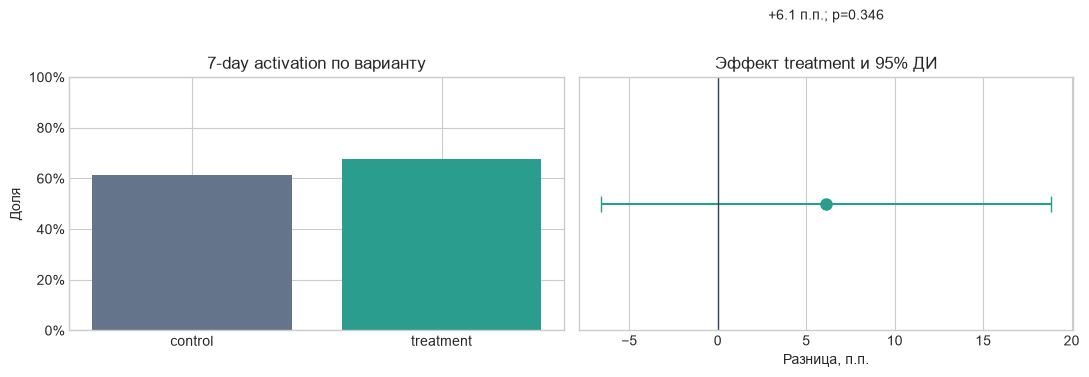

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(
    balance["onboarding_variant"], balance["activation_rate"],
    color=[COLORS[value] for value in balance["onboarding_variant"]],
)
axes[0].set(title="7-day activation по варианту", ylabel="Доля", xlabel="")
axes[0].set_ylim(0, 1)
axes[0].yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
effect = result["absoluteEffect"] * 100
if result["ciLow"] is not None:
    axes[1].errorbar(
        effect, 0,
        xerr=[[effect - result["ciLow"] * 100], [result["ciHigh"] * 100 - effect]],
        fmt="o", color=COLORS["treatment"], capsize=6, markersize=8,
    )
else:
    axes[1].text(0.5, 0.5, "ДИ не оценивается: мало наблюдений",
                 transform=axes[1].transAxes, ha="center")
axes[1].axvline(0, color="#334155", linewidth=1)
axes[1].set(title="Эффект treatment и 95% ДИ", xlabel="Разница, п.п.", yticks=[])
p_text = format(result["pValue"], ".3f") if result["pValue"] is not None else "-"
axes[1].text(effect, 0.08, f"{effect:+.1f} п.п.; p={p_text}", ha="center")
plt.tight_layout();

In [5]:
experiment["link_fetched_7d"] = experiment["first_link_fetched_at"].notna() & (
    experiment["first_link_fetched_at"]
    < experiment["subscription_started_at"] + pd.to_timedelta(7, unit="D")
)
diagnostics = experiment.groupby("onboarding_variant").agg(
    link_fetch_rate=("link_fetched_7d", "mean"),
    median_time_to_value_hours=("time_to_first_value_hours", "median"),
    failed_attempts=("failed_attempts_7d", "sum"),
    total_attempts=("total_attempts_7d", "sum"),
)
diagnostics["connection_failure_rate"] = (
    diagnostics["failed_attempts"] / diagnostics["total_attempts"]
)
diagnostics[["link_fetch_rate", "median_time_to_value_hours", "connection_failure_rate"]]

,link_fetch_rate,median_time_to_value_hours,connection_failure_rate
onboarding_variant,,,
control,0.908257,24.845282,0.082927
treatment,0.925926,17.386311,0.092664


## Takeaways

1. В симуляции разность treatment − control равна **+6.1 п.п.**. Доверительный интервал пересекает ноль.
2. Нельзя объявлять победителя только по положительному point estimate: текущая выборка **217**, расчётная **478**.
3. Для реальной проверки нужны независимая рандомизация, заранее заданные выборка и правило остановки, контроль ошибок подключения. Дополнительные синтетические строки не заменяют эксперимент на реальных пользователях.